In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/creditcard.csv")

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# 1. Exploratory Data Analysis (EDA)
## 1.1 Preliminary Data Exploration
### Data Content: 
1. Features (V1-V28) undergoes PCA transformation (justified from Kaggle Source https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud?resource=download), Original features not provided due to confidentiality issues.
2. Features have not been transformed with PCA are ***"Time"*** and ***"Amount"***. Feature ***"Time"*** contains the seconds elapsed between each transaction and the first transaction in the dataset. 
3. The feature ***"Amount"*** is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. 
4. Feature ***"Class"*** is the response variable (Target variable) and it takes value 1 case of fraud and 0 otherwise.
5. Given the class imbalance ratio, recommend measuring the accuracy using the Area Under the Precision-Recall Curve (AUPRC). Confusion Matrix accuracy is not meaningful for unbalanced classification.



In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

### Data size 
- 284807 Rows (Transactions)
- 31 columns (Features and Target)

In [15]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [16]:

print(df["Class"].value_counts(normalize=True) * 100)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


### Observe Target Class
This indicates highly imbalanced between 2 classes (492 Fraud 0.2%) and (284315 not Fraud 99.8%)

In [17]:
## Understand Numerical distributions 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [18]:
# Check missing values 
df.isnull().sum().sum()

np.int64(0)

### No Missing Values!

In [19]:
# Check duplicates 
df.duplicated().sum()

np.int64(1081)

Apparently, there are 1081 duplicate records. these could be bulk transactions with same amount at the same time. 

In [20]:
# Display the dupplicated records 
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284192,172233.0,-2.691642,3.123168,-3.339407,1.017018,-0.293095,-0.167054,-0.745886,2.325616,-1.634651,...,0.402639,0.259746,-0.086606,-0.097597,0.083693,-0.453584,-1.205466,-0.213020,36.74,0
284193,172233.0,-2.691642,3.123168,-3.339407,1.017018,-0.293095,-0.167054,-0.745886,2.325616,-1.634651,...,0.402639,0.259746,-0.086606,-0.097597,0.083693,-0.453584,-1.205466,-0.213020,36.74,0
284190,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


In [22]:
# Check distribution of duplicated records 
df[df.duplicated(keep=False)]["Class"].value_counts()

Class
0    1822
1      32
Name: count, dtype: int64

# 2. Data Visualization and Correlation Analysis

Text(0, 0.5, 'Number of Transaction')

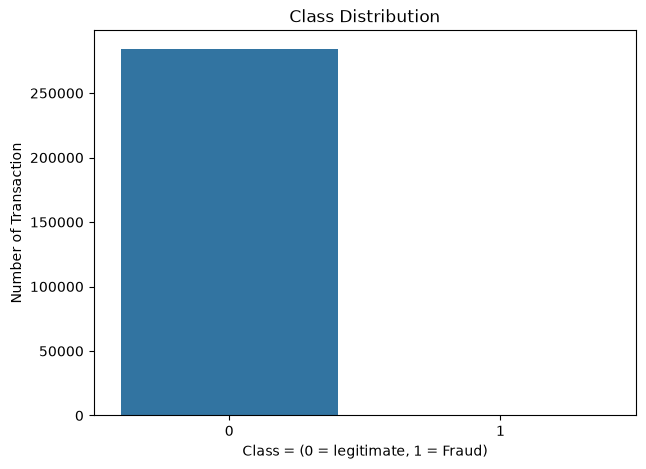

In [25]:
# Understand how many legitimate and fraudulent transaction exist 
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Class")

plt.title("Class Distribution")
plt.xlabel("Class = (0 = legitimate, 1 = Fraud)")
plt.ylabel("Number of Transaction")

This clearly shown the heavy unbalanced of the class in the dataset.

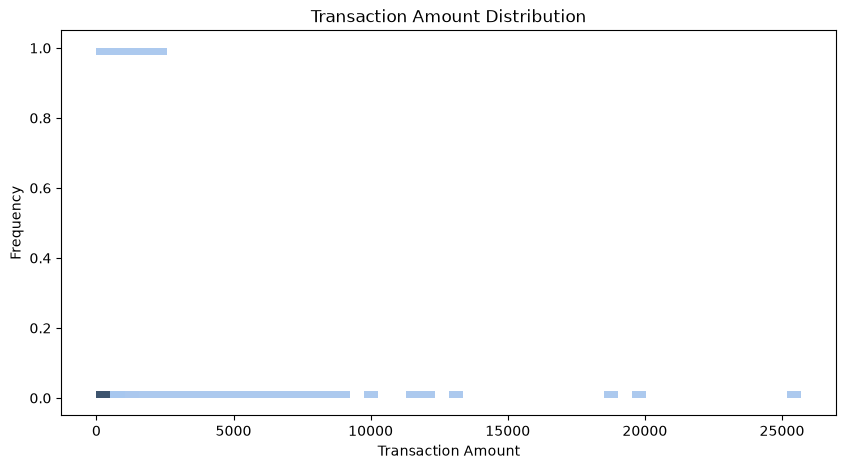

In [ ]:
# Transaction Amount distribution 
# To understand whether fraudulent transactions have different transaction amounts.
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="Amount",
    y="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

### Transaction Amount VS Target Analysis
from the distribution graph above, the fraudulent transactions Amount ranges between 0-3000, while legitimate transactions Amount spread from 0-28000

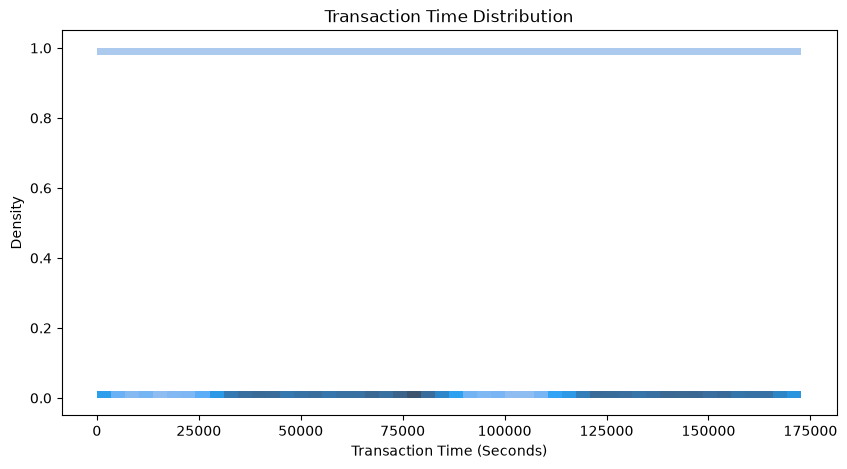

In [37]:
# Transaction Time Distribution 
# To understand whether fraudulent transactions occurs at different times.
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x="Time",
    y="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution")
plt.xlabel("Transaction Time (Seconds)")
plt.ylabel("Density")

plt.show()

### Transaction Time VS Class Distribution Analysis
Seems like the transaction time does not significantly distinguish between the Type of transaction ( Both spread widely from 0-175000 seconds )

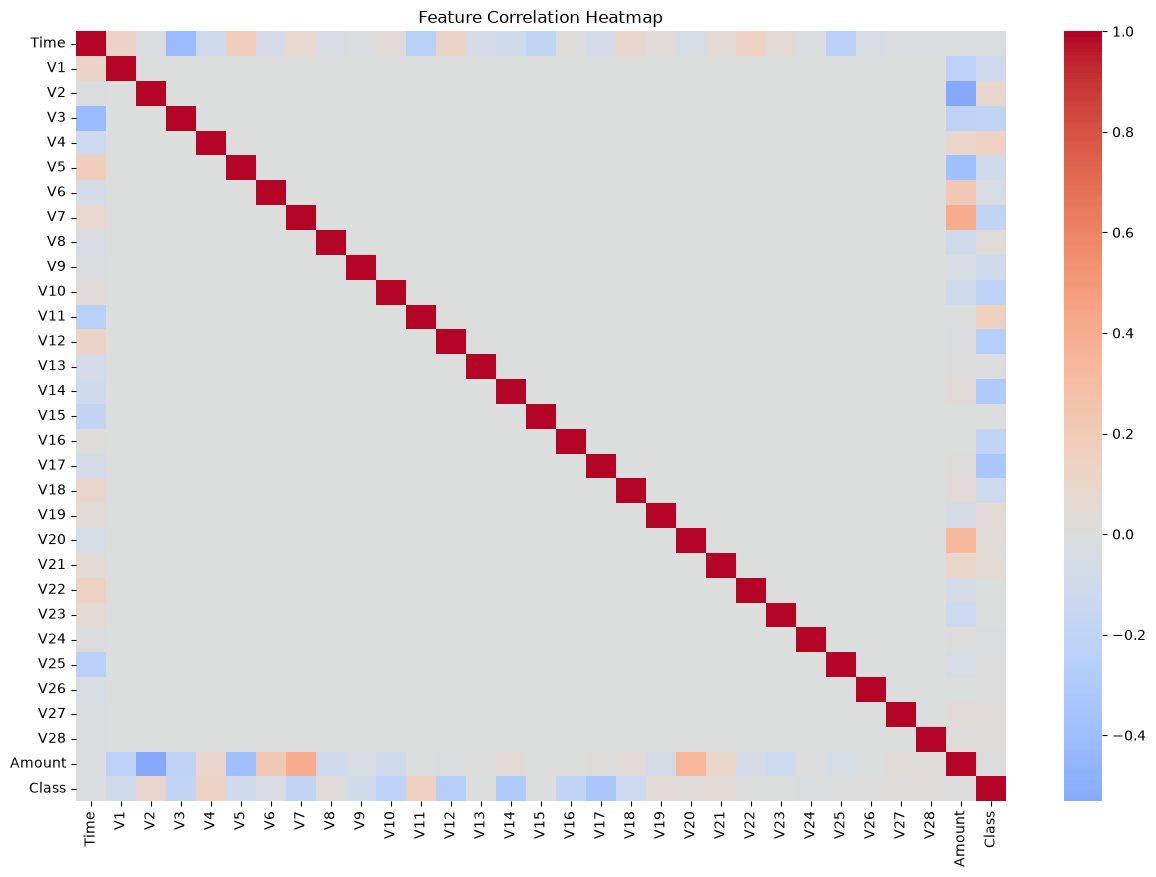

In [38]:
### Correlation Analysis
plt.figure(figsize=(15,10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.show()

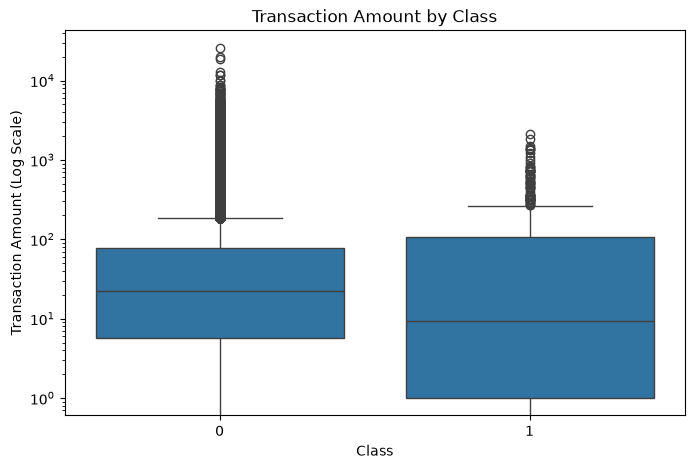

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.yscale("log")

plt.title("Transaction Amount by Class")
plt.xlabel("Class")
plt.ylabel("Transaction Amount (Log Scale)")

plt.show()

In [40]:
### Train Test Split 

# Separate features and Target

X = df.drop("Class", axis=1)
y = df["Class"]

print("Features Shape:", X.shape)
print("Class Shape:", y.shape)

Features Shape: (284807, 30)
Class Shape: (284807,)


In [44]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
# Check the split results 
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (227845, 30)
Testing features: (56962, 30)

Training target distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing target distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [46]:
# Compare class percentage 
print("Training class percentage:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class percentage:")
print(y_test.value_counts(normalize=True) * 100)


Training class percentage:
Class
0    99.827075
1     0.172925
Name: proportion, dtype: float64

Testing class percentage:
Class
0    99.827955
1     0.172045
Name: proportion, dtype: float64


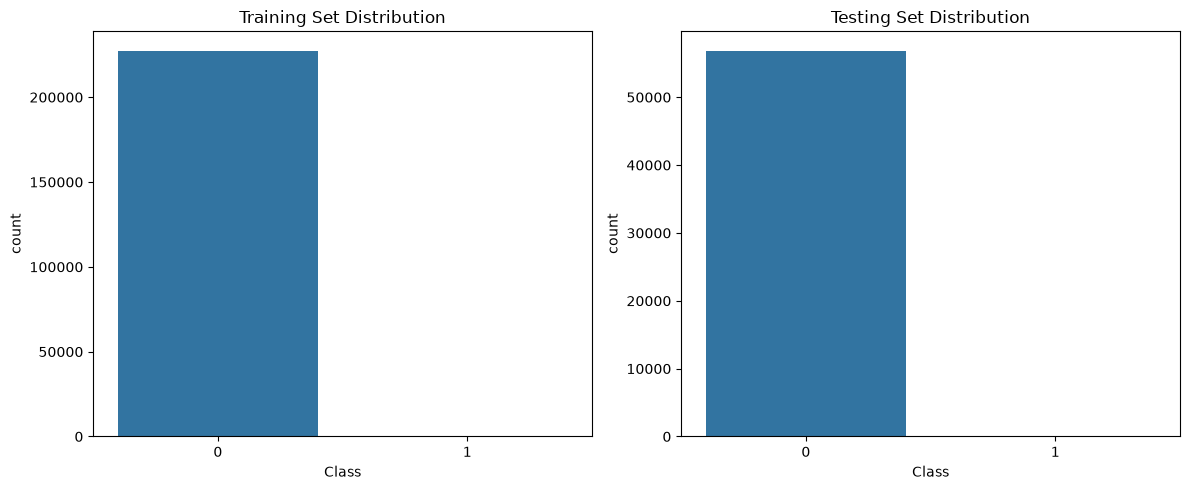

In [47]:
# Visualize the split

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Training Set Distribution")
axes[0].set_xlabel("Class")

sns.countplot(x=y_test, ax=axes[1])
axes[1].set_title("Testing Set Distribution")
axes[1].set_xlabel("Class")

plt.tight_layout()
plt.show()

In [50]:
# TESTING Model Fitting 
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

logreg = LogisticRegression()

logreg.fit(X_train,y_train)

# Display the model's learned coefficients
print(f"Intercept: {logreg.intercept_}")
print(f"Coefficient: {logreg.coef_[0]}")

# Make predictions on the testing set
y_pred = logreg.predict(X_test)

# Display the predictions
print("Predicted Outcomes (Pass/Fail):", y_pred)
print("Actual Outcomes:", y_test.values)

Intercept: [-1.72150378]
Coefficient: [-8.54659482e-05  4.44735304e-01 -7.94523482e-01 -8.05512086e-01
  2.00353573e-01  2.10719863e-01 -1.55111486e-01  3.86334398e-01
 -3.53908266e-01 -5.46804709e-01 -3.37395643e-01 -2.45035036e-01
 -1.53036978e-02 -4.42350450e-01 -1.06843182e+00 -4.23679129e-01
 -4.20909824e-01 -7.45705601e-01 -4.75338682e-02  5.08957459e-02
  6.09279054e-02  3.10240074e-01  3.65616199e-01  4.72411066e-02
 -2.30117490e-02 -3.72161800e-01  5.07112783e-02 -7.26811492e-02
  8.99229859e-02 -7.64121725e-03]
Predicted Outcomes (Pass/Fail): [0 0 0 ... 0 0 0]
Actual Outcomes: [0 0 0 ... 0 0 0]


/opt/anaconda3/envs/fraudenv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [51]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Generate classification report
class_report = classification_report(y_test, y_pred)

# Display evaluation metrics
print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.9990519995786665
Confusion Matrix:
[[56836    28]
 [   26    72]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.72      0.73      0.73        98

    accuracy                           1.00     56962
   macro avg       0.86      0.87      0.86     56962
weighted avg       1.00      1.00      1.00     56962



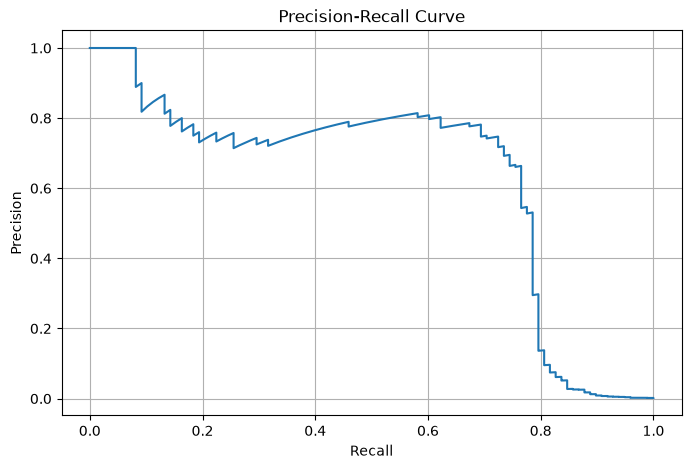

In [54]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Get predicted probabilities
y_prob = logreg.predict_proba(X_test)[:, 1]

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.grid()
plt.show()

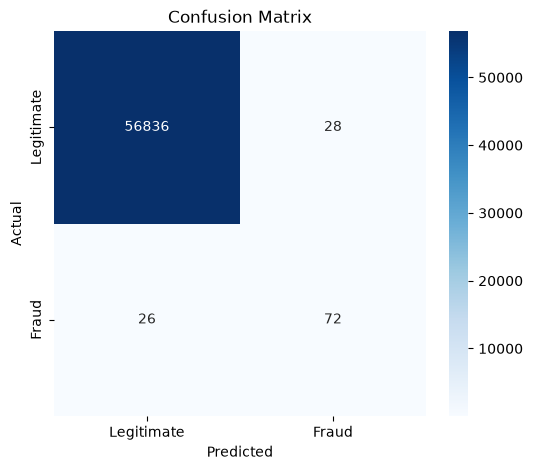

In [55]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

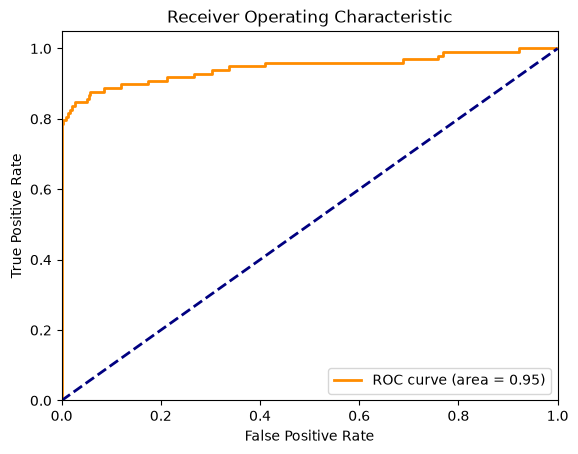

In [56]:
# Plotting the ROC Curve
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()